# Brain Tumor MRI Image Classification

**Project type:** Multiclass image classification  
**Contribution:** Individual  
**Domain:** Medical imaging research

## Project summary (500–600 words)

This project studies four-class classification of brain MRI images into glioma, meningioma, pituitary tumor, and no tumor. The supplied Roboflow export contains 2,443 JPEG images with predefined training, validation, and test directories. The project brief asks for a custom convolutional neural network, transfer learning, model comparison, and a Streamlit application that predicts a class from an uploaded image. This notebook connects those steps in a reproducible workflow and keeps the same class order from data loading through deployment.

Before modeling, we audited the archive and found a serious split problem: multiple image variants carrying the same source-image identifier appeared in different supplied splits, especially for glioma. A random image-level split would let a model see a variant of an evaluation image during training. We therefore reconstructed the split at the source-image level, preserving all images and approximately the original train, validation, and test proportions. The cleaned dataset has 1,696 training, 500 validation, and 247 test images. Every image is listed in a manifest with its original split, new split, source ID, and SHA-256 digest. No named source image crosses the new splits. Patient identifiers are unavailable, so this does not guarantee patient-level separation.

Exploratory analysis focuses on the training split. Fifteen charts examine class balance, examples, pixel brightness, contrast, entropy, edges, color channels, feature relationships, and augmentation multiplicity. Three planned Kruskal-Wallis tests compare source-level brightness, edge strength, and entropy across classes with Holm correction. These image statistics can reveal dataset or acquisition differences; a significant p-value does not prove a medically meaningful tumor feature. A simple balanced logistic-regression baseline uses nine image measurements and three-fold stratified group cross-validation to tune its regularization strength. It provides context for the deep models, but it cannot capture the spatial detail available to a CNN.

The main experiments train a custom CNN with convolution, batch normalization, pooling, and dropout, plus MobileNetV2 and EfficientNetB0 classifiers initialized with ImageNet weights. The transfer backbones are frozen for the initial experiments, followed by a small MobileNetV2 fine-tuning pass. Images are resized to 160 by 160 pixels. Each model includes the preprocessing appropriate to its backbone, while moderate random transformations are applied only during training. A short source-grouped cross-validation screen compares two learning rates per deep model. Early stopping monitors validation loss, and the best checkpoint is saved. The models are compared with validation accuracy, macro precision, macro recall, and macro F1. Macro scores give each class equal weight. The deployment choice is fixed using validation macro F1 before the held-out test set is evaluated.

The Streamlit application loads the selected HDF5 model, accepts a JPG or PNG MRI image, and displays the predicted class and four model scores. An occlusion view offers a limited explanation of one prediction by showing which image regions change its score when hidden. The application and deployment bundle are included, but their outputs are research demonstrations. The dataset has no patient IDs or external hospital cohort, the labels have not been independently verified, and the model scores are not calibrated clinical probabilities. Interpretation remains cautious because image labels alone cannot establish clinical validity. External validation, subgroup checks, and specialist review would be necessary before considering use in healthcare decisions.

## Problem statement and GitHub

Build and compare a custom CNN and pretrained image classifiers for four MRI categories, then provide a Streamlit upload interface. This is an educational research project, not a diagnostic tool.

**GitHub repository:** https://github.com/vivekvx/brain-tumor-mri-classification

**Potential use cases after clinical validation:** radiologist decision support, specialist triage, research cohort grouping, and remote second opinions. None is established by this image-level benchmark; false negatives, scanner shifts, and label quality must be assessed with patient-level external data first.

## 1. Know your data

The source is a Roboflow JPEG export with four folders and one-hot CSV labels. The following cell validates that the cleaned split is present, preparing it from `BRAIN_MRI_ZIP` if needed. Set that environment variable to the source ZIP path on a new machine.

In [1]:
import os, sys, subprocess, json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

if not Path('data/cleaned/manifest.csv').exists():
    source_zip = os.environ.get('BRAIN_MRI_ZIP')
    if not source_zip:
        raise FileNotFoundError('Set BRAIN_MRI_ZIP to the supplied dataset ZIP before running this notebook.')
    subprocess.run([sys.executable, 'scripts/prepare_dataset.py', '--source', source_zip], check=True)
manifest = pd.read_csv('data/cleaned/manifest.csv')
display(pd.crosstab(manifest['class'], manifest['new_split']))
print('Rows:', len(manifest), 'classes:', sorted(manifest['class'].unique()))
print('Missing values:', int(manifest.isna().sum().sum()))
print('Duplicate output paths:', int(manifest.duplicated(['new_split', 'class', 'filename']).sum()))
print('Source groups crossing splits:', int((manifest.groupby(['class','source_id'])['new_split'].nunique() > 1).sum()))

new_split,test,train,valid
class,,,
glioma,81,560,164
meningioma,55,378,112
no_tumor,49,335,99
pituitary,62,423,125


Rows: 2443 classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Missing values: 0
Duplicate output paths: 0
Source groups crossing splits: 0


**Data understanding and wrangling.** Every image is 640 × 640 RGB before modeling; all files opened successfully during audit. The supplied CSV labels matched their folders. Duplicate augmented variants are kept together in the new split. Missing tabular values, text cleaning, categorical feature encoding, and outlier removal are not applicable to the raw MRI image input. The class label is encoded by the folder loader as an integer from 0 to 3. Source-image grouping reduces known leakage, although patient-level grouping is impossible without patient IDs.

## 2. Exploratory analysis: 15 charts

The charts below use the training images for image features. Split counts use the manifest. Each chart has a purpose, observation, and practical implication; observations about pixel statistics may reflect scanner or preparation differences.

In [2]:
if not Path('reports/hypothesis_tests.json').exists():
    subprocess.run([sys.executable, '-m', 'src.eda'], check=True)
features = pd.read_csv('reports/image_features.csv')
display(features.head())

,filename,split,class,source_id,file_kb,brightness,contrast,entropy,edge_strength,center_brightness,border_brightness,red_mean,green_mean,blue_mean
0,Tr-gl_0016_jpg.rf.99746694ea97fe0b73108832b462...,train,glioma,Tr-gl_0016,28.125000,0.131823,0.152255,2.971583,0.036682,0.246232,0.027062,0.131823,0.131823,0.131823
1,Tr-gl_0018_jpg.rf.7a670766b8083a1b516a49e241a6...,train,glioma,Tr-gl_0018,26.443359,0.121784,0.129593,3.007586,0.030502,0.216379,0.030285,0.121784,0.121784,0.121784
2,Tr-gl_0028_jpg.rf.8098b9737048aac0dccb1b7c4504...,valid,glioma,Tr-gl_0028,31.201172,0.147756,0.144473,3.317955,0.038894,0.242115,0.053002,0.147756,0.147756,0.147756
3,Tr-gl_0032_jpg.rf.e1e485b4f909d84c8e24cd26e0ad...,train,glioma,Tr-gl_0032,31.427734,0.189673,0.183793,3.427146,0.038029,0.346274,0.049286,0.189673,0.189673,0.189673
4,Tr-gl_0035_jpg.rf.7a7c96ab2e6245cf42a0c86b97f8...,train,glioma,Tr-gl_0035,27.150391,0.129495,0.149999,2.835505,0.031760,0.238496,0.047185,0.129495,0.129495,0.129495


### Chart 1: Train Class Counts

- **Why this chart?** A count chart makes training class balance visible.
- **Insight:** Glioma has 560 images and no tumor has 335; class sizes differ but none is absent.
- **Potential impact or risk:** Macro metrics and per-class recall are needed so the largest class does not dominate evaluation.

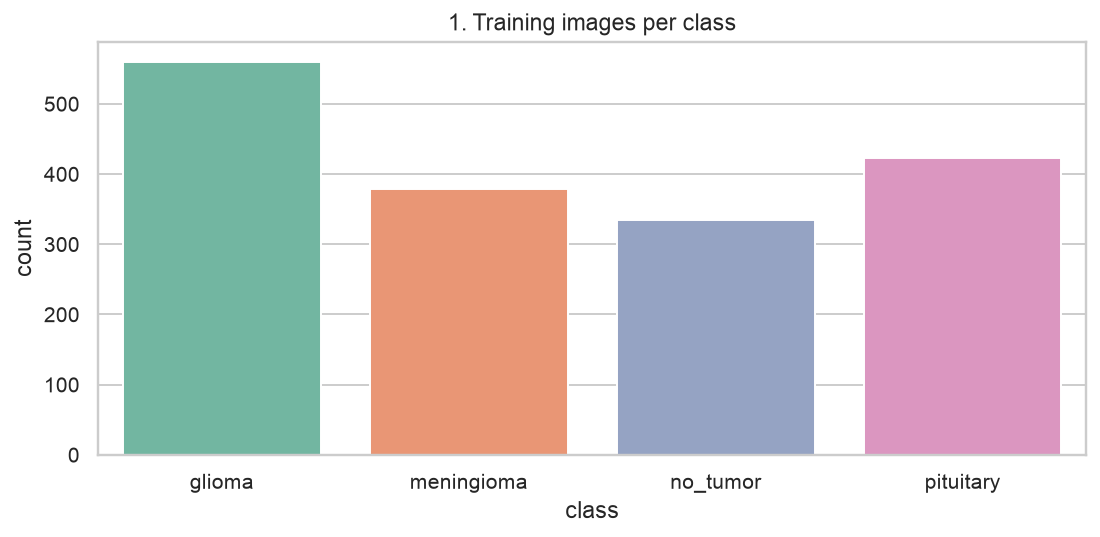

In [3]:
display(Image(filename='reports/figures/01_train_class_counts.png'))

### Chart 2: Split Class Mix

- **Why this chart?** Stacked proportions check the reconstructed split.
- **Insight:** The four class shares remain similar across train, validation, and test.
- **Potential impact or risk:** Comparable split composition supports a fairer validation comparison; source-level leakage is checked separately.

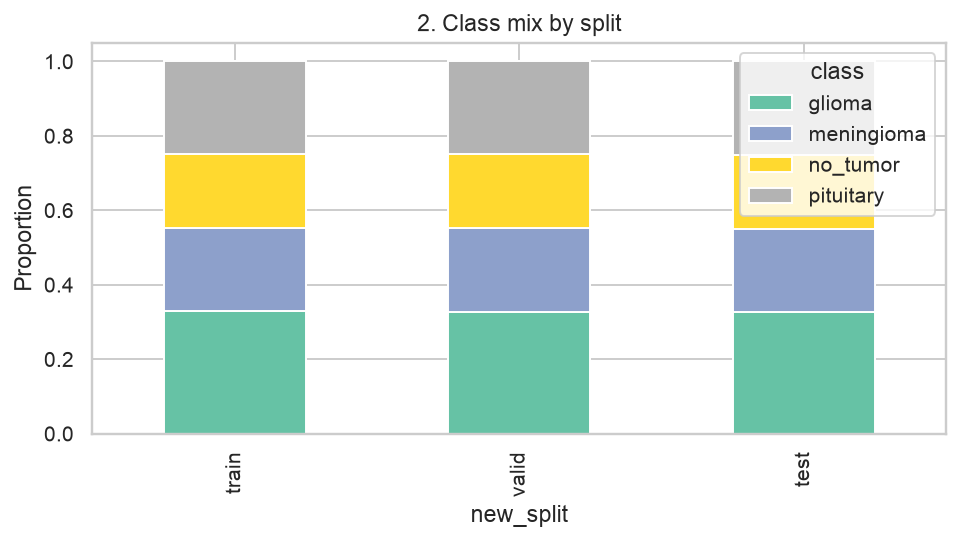

In [4]:
display(Image(filename='reports/figures/02_split_class_mix.png'))

### Chart 3: Class Examples

- **Why this chart?** A montage reveals visual diversity that summary statistics miss.
- **Insight:** Orientation and image appearance vary within classes.
- **Potential impact or risk:** Augmentation and external validation matter when scans may come from different acquisition settings.

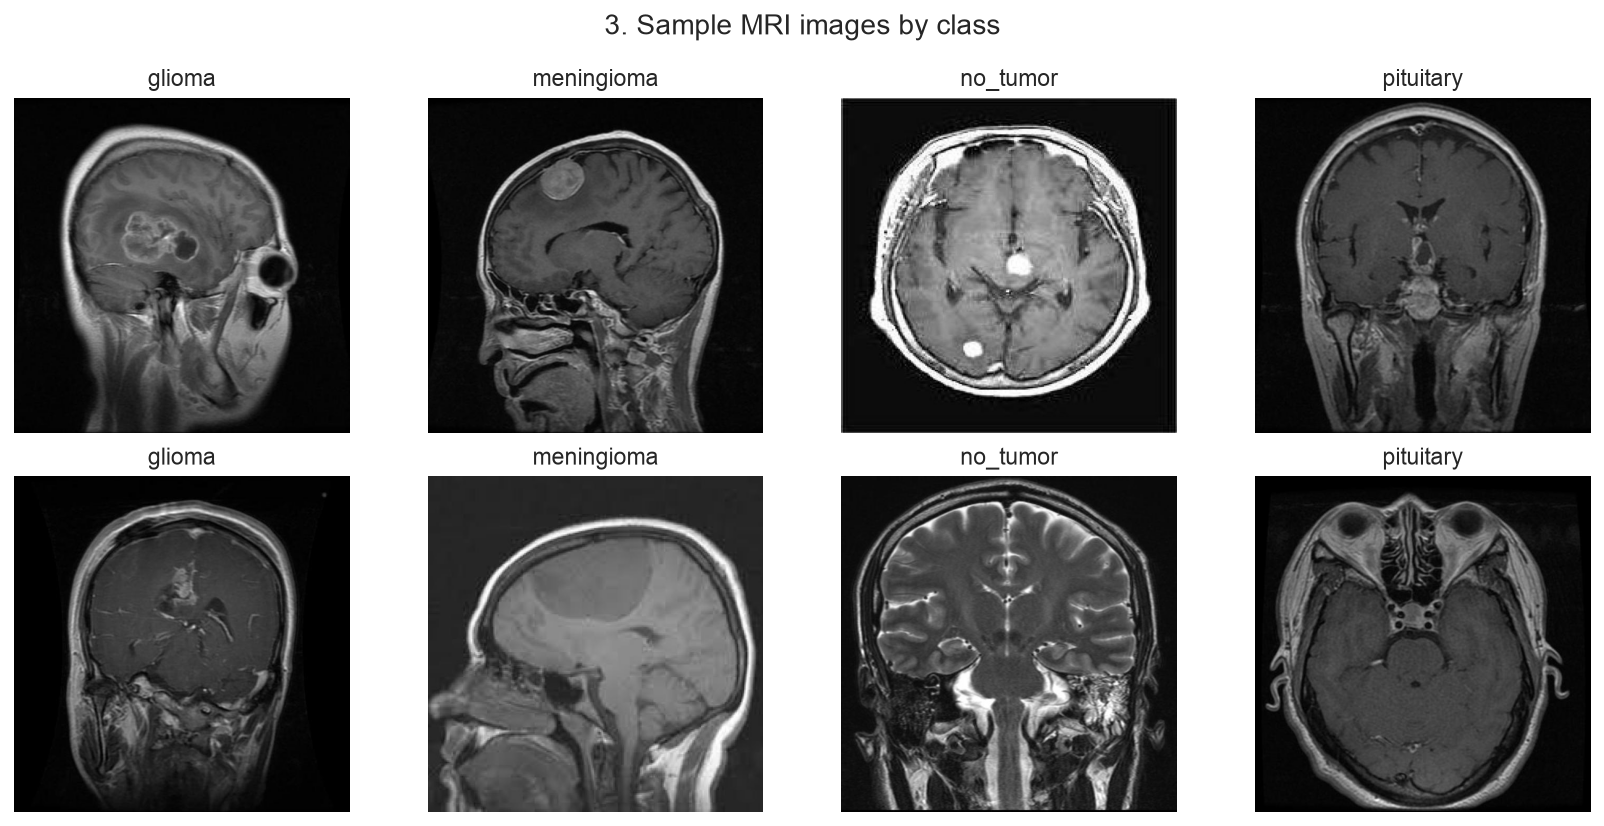

In [5]:
display(Image(filename='reports/figures/03_class_examples.png'))

### Chart 4: File Kb

- **Why this chart?** File size can expose compression or image-source differences.
- **Insight:** Median training JPEG size ranges from 23.2 to 39.0 KB across classes.
- **Potential impact or risk:** A classifier must not rely on source or compression artifacts as a shortcut.

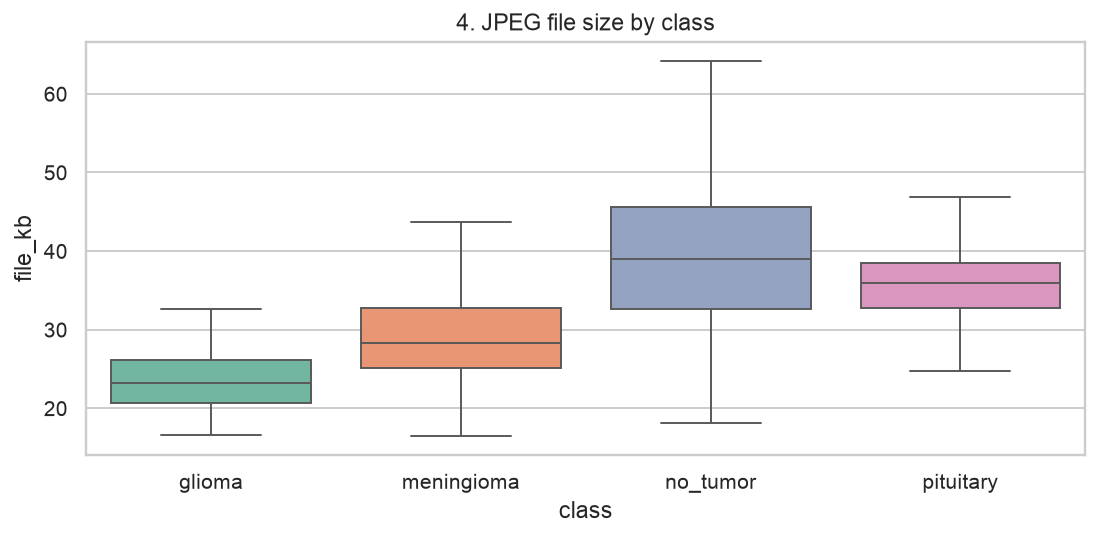

In [6]:
display(Image(filename='reports/figures/04_file_kb.png'))

### Chart 5: Brightness

- **Why this chart?** Boxplots compare the image brightness distributions.
- **Insight:** Median brightness is 0.104 for glioma and 0.221 for no tumor.
- **Potential impact or risk:** Large brightness differences may reflect acquisition or preprocessing; robustness checks are needed.

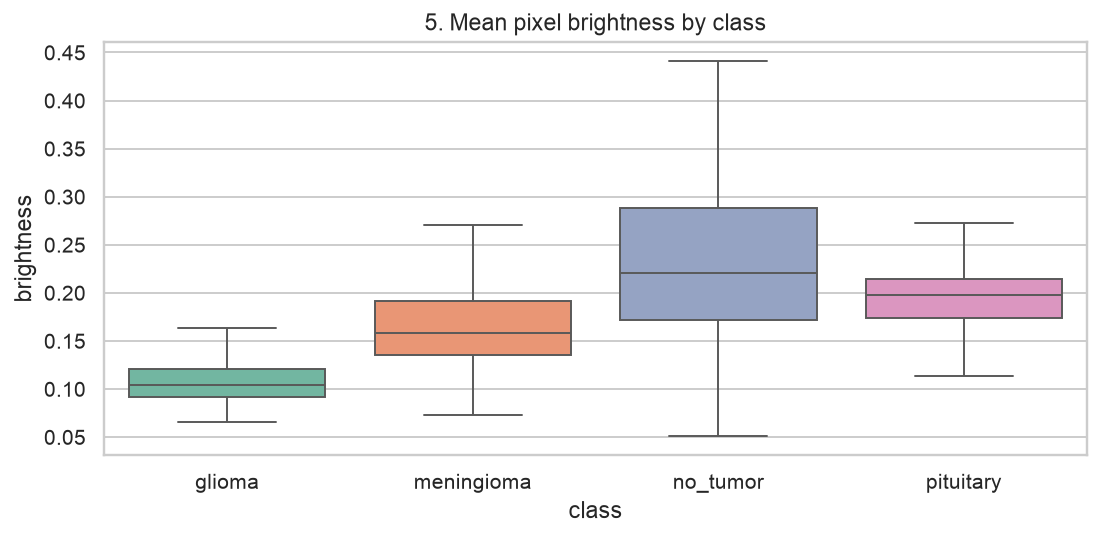

In [7]:
display(Image(filename='reports/figures/05_brightness.png'))

### Chart 6: Contrast

- **Why this chart?** Contrast summarizes variation inside each image.
- **Insight:** Class median contrast spans 0.134–0.204.
- **Potential impact or risk:** Contrast variation can affect model generalization to other scanners.

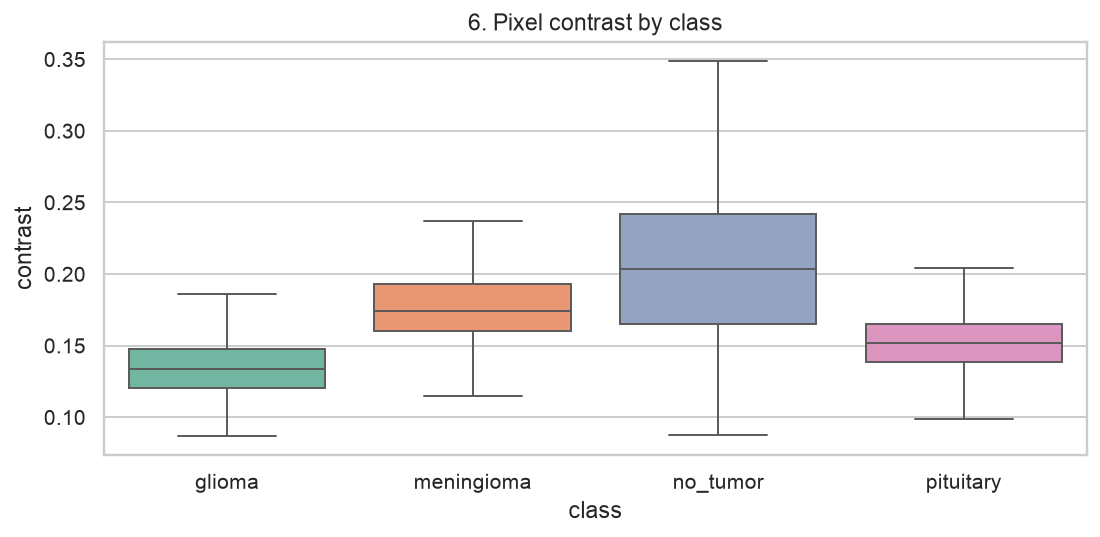

In [8]:
display(Image(filename='reports/figures/06_contrast.png'))

### Chart 7: Entropy

- **Why this chart?** Entropy captures how spread out pixel intensities are.
- **Insight:** Class median entropy spans 2.35–3.62 bits.
- **Potential impact or risk:** An entropy difference is a dataset signal, not evidence of a clinical imaging marker.

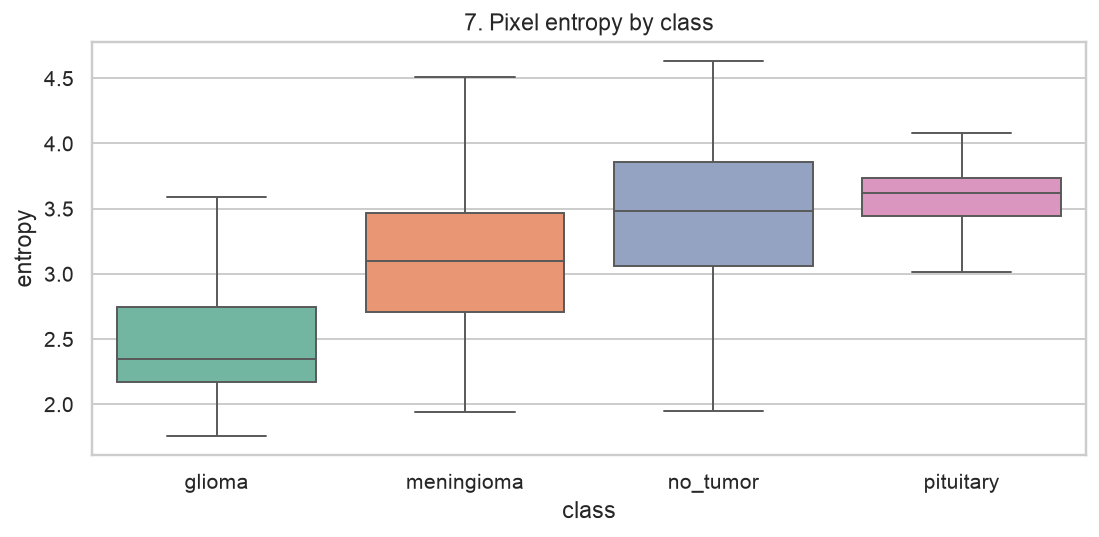

In [9]:
display(Image(filename='reports/figures/07_entropy.png'))

### Chart 8: Edge Strength

- **Why this chart?** Edge strength measures local intensity transitions.
- **Insight:** Class median edge strength spans 0.027–0.054.
- **Potential impact or risk:** Different edge profiles may reveal scanner or resolution effects that require validation.

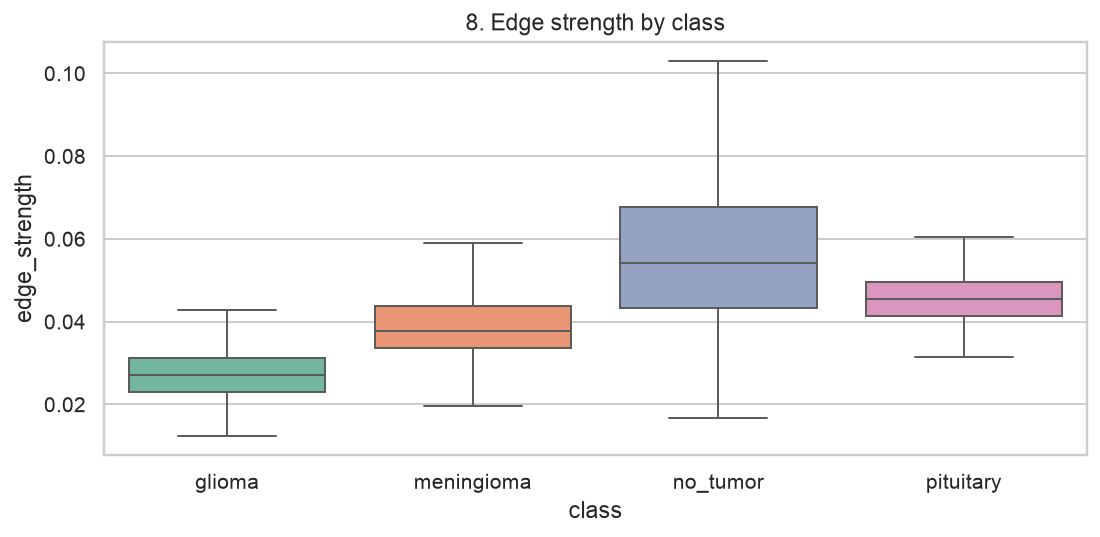

In [10]:
display(Image(filename='reports/figures/08_edge_strength.png'))

### Chart 9: Center Brightness

- **Why this chart?** Center brightness checks where signal is concentrated.
- **Insight:** Class median center brightness spans 0.237–0.378.
- **Potential impact or risk:** A shortcut based on framing would be unreliable outside this collection.

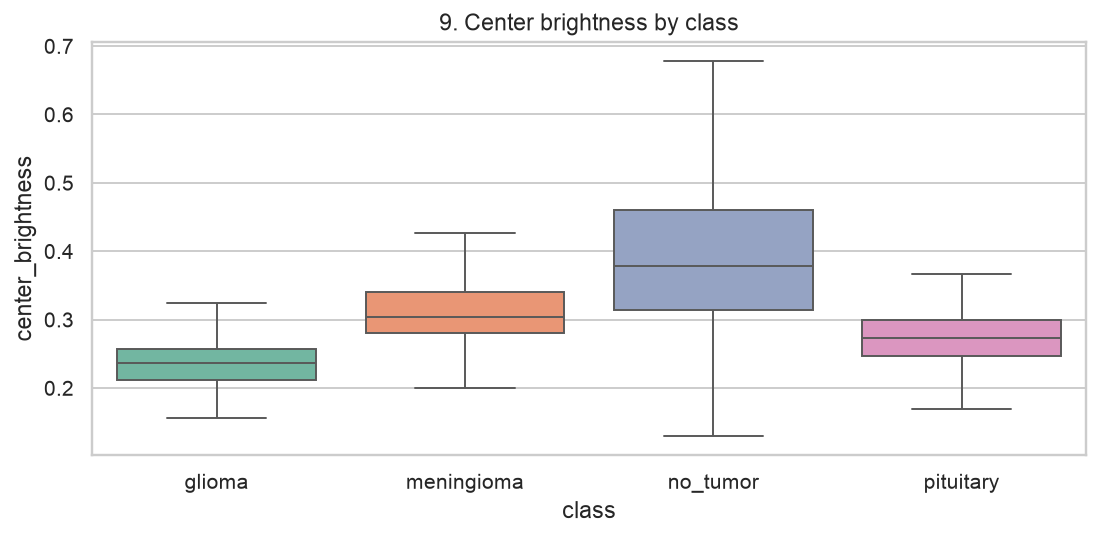

In [11]:
display(Image(filename='reports/figures/09_center_brightness.png'))

### Chart 10: Channel Means

- **Why this chart?** Channel means check whether these RGB files contain meaningful color.
- **Insight:** The three channels are similar because the source scans are visually close to grayscale.
- **Potential impact or risk:** The app still accepts RGB files and uses the same three-channel model input.

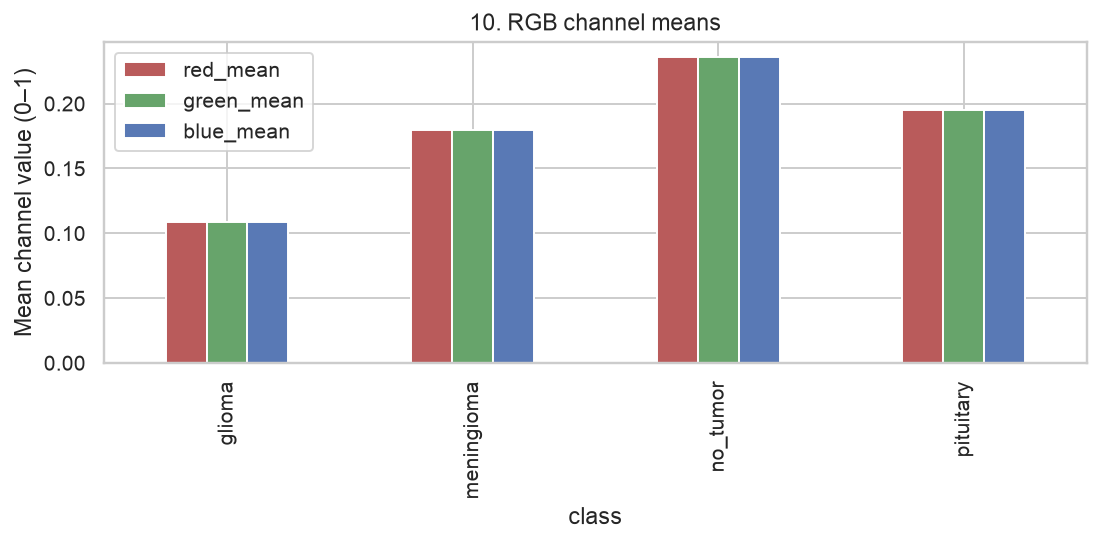

In [12]:
display(Image(filename='reports/figures/10_channel_means.png'))

### Chart 11: Brightness Contrast

- **Why this chart?** A scatterplot exposes joint distributions and outliers.
- **Insight:** Brightness and contrast have correlation 0.73; classes overlap.
- **Potential impact or risk:** A single image statistic cannot replace a spatial image model.

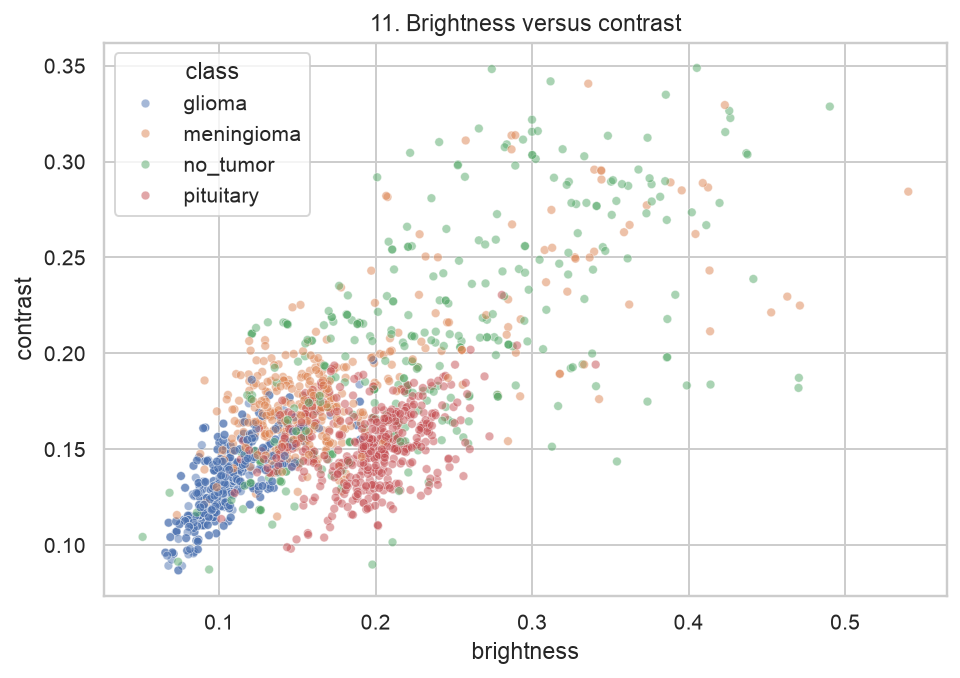

In [13]:
display(Image(filename='reports/figures/11_brightness_contrast.png'))

### Chart 12: Brightness Edges

- **Why this chart?** This view checks whether brighter images also have stronger edges.
- **Insight:** Brightness and edge strength have correlation 0.88.
- **Potential impact or risk:** Correlated low-level signals could enable shortcut learning; model validation should cover new sources.

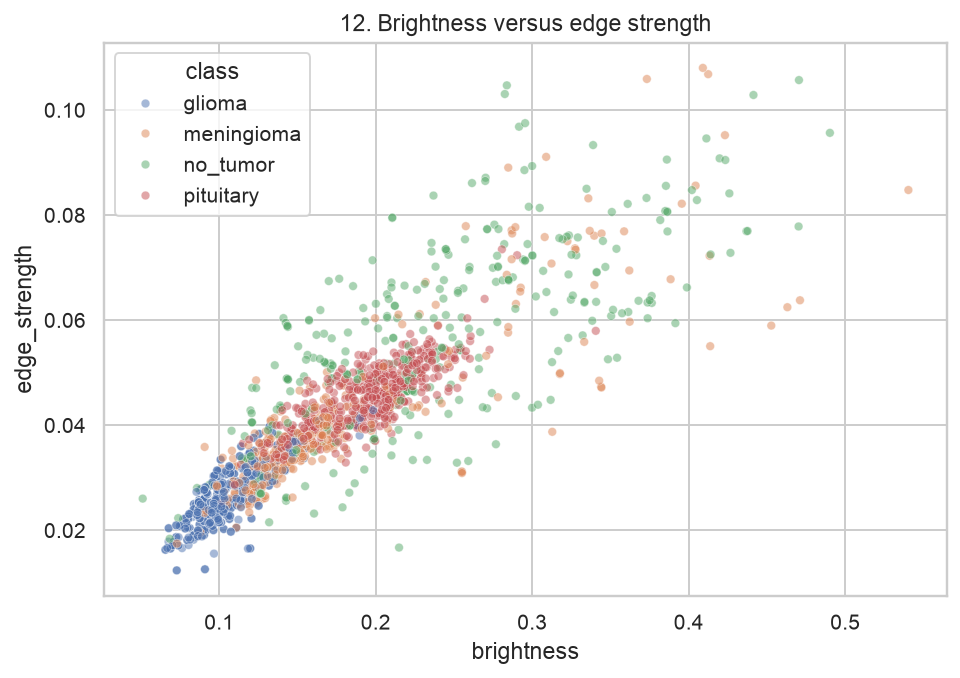

In [14]:
display(Image(filename='reports/figures/12_brightness_edges.png'))

### Chart 13: Feature Correlation

- **Why this chart?** A heatmap summarizes redundant image measurements.
- **Insight:** Several low-level features are correlated, so they are not independent sources of evidence.
- **Potential impact or risk:** The feature baseline uses scaling and cross-validation rather than interpreting coefficients clinically.

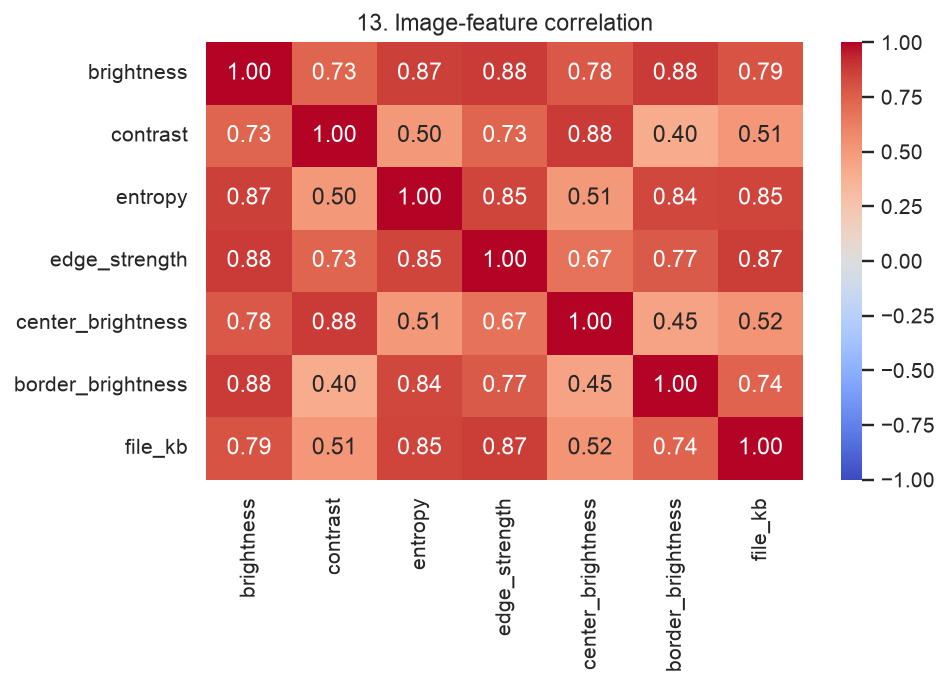

In [15]:
display(Image(filename='reports/figures/13_feature_correlation.png'))

### Chart 14: Feature Pairplot

- **Why this chart?** Pairwise plots show class overlap across three measurements.
- **Insight:** The classes overlap in this low-dimensional feature view.
- **Potential impact or risk:** CNNs can use spatial detail that summary features discard, but still require held-out testing.

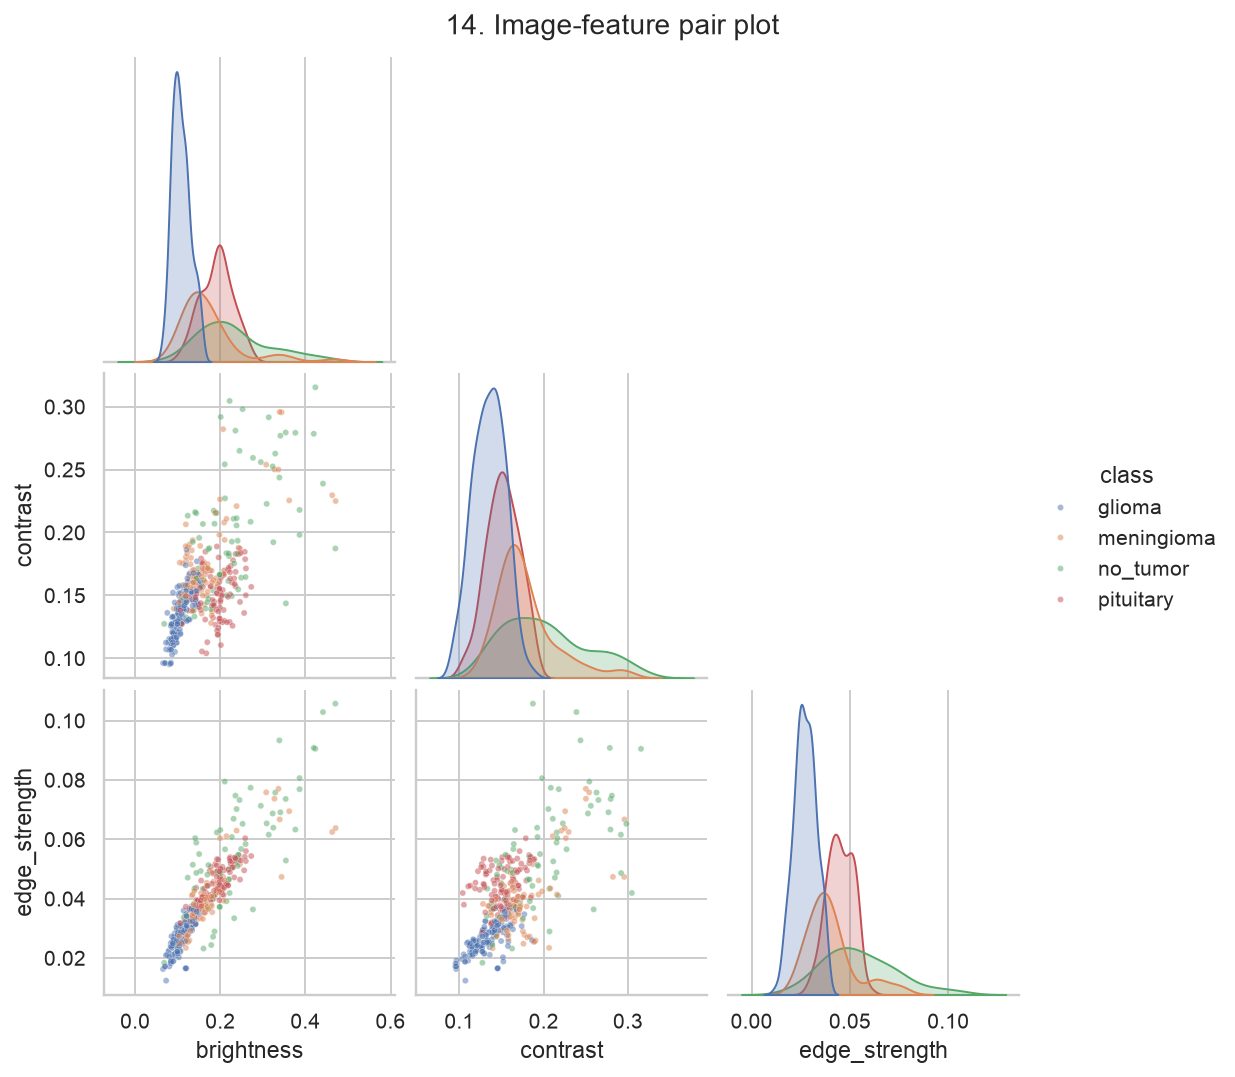

In [16]:
display(Image(filename='reports/figures/14_feature_pairplot.png'))

### Chart 15: Source Variants

- **Why this chart?** Source multiplicity reveals augmentation and split risks.
- **Insight:** Glioma contains repeated variants of named source images; the other classes mostly contain one variant each.
- **Potential impact or risk:** Grouping by source ID prevents known variants from leaking into validation or test.

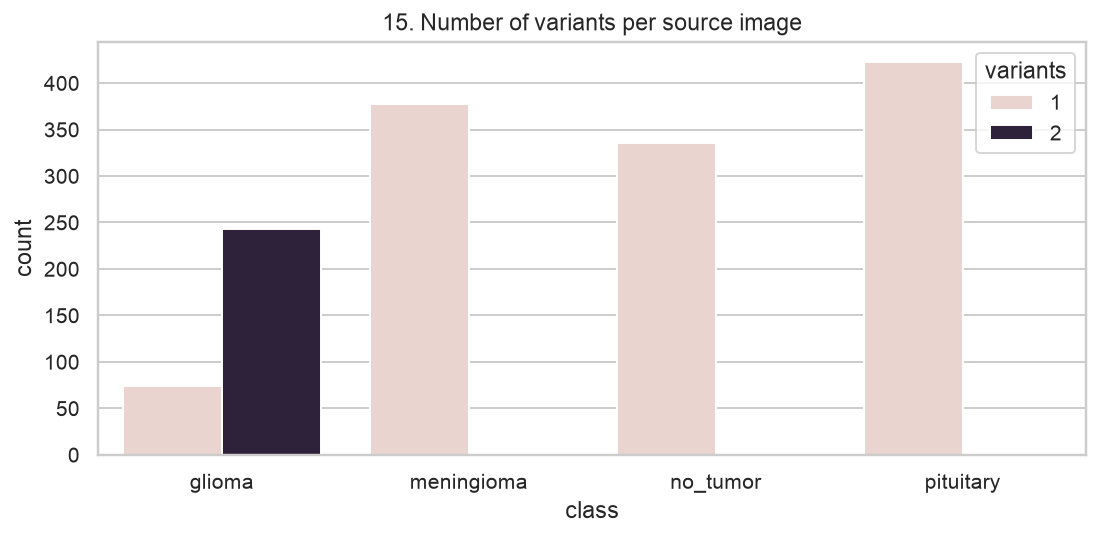

In [17]:
display(Image(filename='reports/figures/15_source_variants.png'))

## 3. Hypothesis testing

The three tests were specified for training data. Augmented variants are averaged within each named source image before testing. Kruskal–Wallis compares class distributions without assuming normality; Holm adjustment accounts for three planned tests. These are exploratory dataset comparisons, not clinical conclusions.

In [18]:
tests = json.loads(Path('reports/hypothesis_tests.json').read_text())
display(pd.DataFrame([{'feature': key, 'H statistic': value['statistic'], 'p value': value['p_value'], 'Holm p': value['p_holm']} for key, value in tests.items()]))

,feature,H statistic,p value,Holm p
0,brightness,706.864389,6.816624e-153,1.363325e-152
1,edge_strength,739.237315,6.509909e-160,1.952973e-159
2,entropy,627.366743,1.176072e-135,1.176072e-135


### Hypothesis 1: Brightness

- **H₀:** The distribution of brightness is the same across all four classes.
- **H₁:** At least one class has a different brightness distribution.
- **Test and reason:** Kruskal–Wallis on source-level means accommodates four independent groups without requiring normality.
- **Result:** H=706.86, p=6.82e-153, Holm-adjusted p=1.36e-152. Reject the null at 0.05. Class differences may reflect acquisition conditions and cannot establish tumor biology.

### Hypothesis 2: Edge Strength

- **H₀:** The distribution of edge_strength is the same across all four classes.
- **H₁:** At least one class has a different edge_strength distribution.
- **Test and reason:** Kruskal–Wallis on source-level means accommodates four independent groups without requiring normality.
- **Result:** H=739.24, p=6.51e-160, Holm-adjusted p=1.95e-159. Reject the null at 0.05. Class differences may reflect acquisition conditions and cannot establish tumor biology.

### Hypothesis 3: Entropy

- **H₀:** The distribution of entropy is the same across all four classes.
- **H₁:** At least one class has a different entropy distribution.
- **Test and reason:** Kruskal–Wallis on source-level means accommodates four independent groups without requiring normality.
- **Result:** H=627.37, p=1.18e-135, Holm-adjusted p=1.18e-135. Reject the null at 0.05. Class differences may reflect acquisition conditions and cannot establish tumor biology.

## 4. Preprocessing and feature engineering

Images are resized to 160 × 160 and loaded as RGB. The custom CNN rescales pixels to 0–1. MobileNetV2 maps raw pixels to −1–1 using its expected ImageNet preprocessing. EfficientNetB0 includes its own rescaling. Training-only augmentation uses modest horizontal flips, rotation, zoom, shifts, and brightness changes. Vertical flips are excluded because they could reverse anatomical orientation. Batch normalization and dropout reduce training instability and overfitting. The largest training class has 560 images and the smallest has 335, so we report macro metrics without synthetic oversampling or deep-model class weighting. No tabular imputation, NLP preprocessing, manual feature selection, or dimensionality reduction is applied to the CNN inputs. The source-disjoint train/validation/test split is retained; the test set is never used for tuning.

## 5. Group cross-validation and hyperparameter tuning baseline

A standardized image-feature logistic regression provides a lightweight baseline. Three-fold `StratifiedGroupKFold` keeps source IDs intact, and grid search compares C = 0.1, 1, and 10 using macro F1. This baseline is tuned only on training data and scored once on validation.

In [19]:
if not Path('reports/cv_results.json').exists():
    subprocess.run([sys.executable, '-m', 'src.cross_validate'], check=True)
cv = json.loads(Path('reports/cv_results.json').read_text())
display(pd.DataFrame({'C': list(cv['cv_by_C']), 'CV macro F1': list(cv['cv_by_C'].values())}))
print('Selected C:', cv['best_C'], 'CV macro F1:', round(cv['cv_macro_f1'], 3), 'validation macro F1:', round(cv['validation']['f1_macro'], 3))

,C,CV macro F1
0,0.1,0.713330
1,1.0,0.727103
2,10.0,0.727470


Selected C: 10.0 CV macro F1: 0.727 validation macro F1: 0.747


The best C was **10.0**. The three-fold mean macro F1 was **0.727** and validation macro F1 was **0.747**. The gain over the weakest C candidate is 0.014. This baseline's strong score also warns that low-level acquisition cues may correlate with labels.

## 6. Deep-learning model implementation and comparison

The custom CNN uses three convolution blocks, batch normalization, max pooling, a dense layer, and dropout. MobileNetV2 and EfficientNetB0 use frozen ImageNet backbones with new dense classification heads. A three-fold source-grouped screen compares two learning rates per model using two epochs per fold. This is a coarse tuning screen, not a full convergence estimate. Final models then train longer with early stopping and best-checkpoint selection. Architecture comparison is performed on validation macro F1.

,model,learning rate,3-fold macro F1
0,custom_cnn,0.001,0.225939
1,custom_cnn,0.0003,0.183144
2,mobilenet_v2,0.0003,0.734395
3,mobilenet_v2,0.0001,0.650997
4,efficientnet_b0,0.0003,0.733841
5,efficientnet_b0,0.0001,0.656120


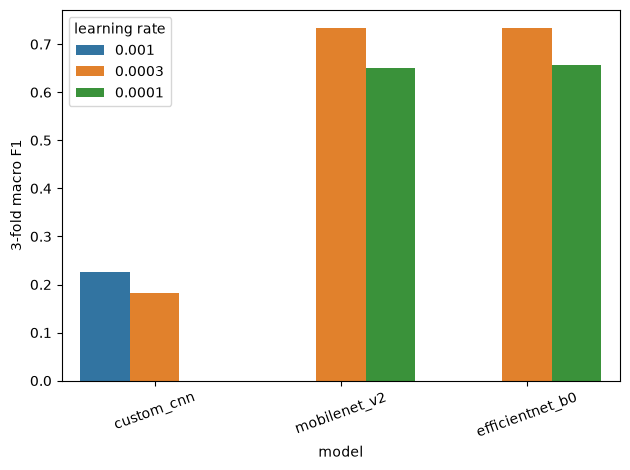

Chosen learning rates: {'custom_cnn': 0.001, 'mobilenet_v2': 0.0003, 'efficientnet_b0': 0.0003}


In [20]:
if not Path('reports/deep_cv.json').exists():
    subprocess.run([sys.executable, '-m', 'src.deep_cv'], check=True)
deep_cv = json.loads(Path('reports/deep_cv.json').read_text())
deep_table = pd.DataFrame([{'model': name, 'learning rate': rate, '3-fold macro F1': stats['mean_f1']} for name, model in deep_cv['models'].items() for rate, stats in model['candidates'].items()])
display(deep_table)
sns.barplot(data=deep_table, x='model', y='3-fold macro F1', hue='learning rate')
plt.xticks(rotation=20); plt.tight_layout(); plt.show()
print('Chosen learning rates:', {name: model['selected_learning_rate'] for name, model in deep_cv['models'].items()})

**Learning-rate tuning outcome.** The chart and table above compare both rates for each architecture. The two-epoch folds are a screening experiment, so these gains should not be read as final-model gains.

- **Custom CNN:** learning rate 0.001 achieved grouped-CV macro F1 0.226, an improvement of 0.043 over the weaker tested rate.
- **MobileNetV2:** learning rate 0.0003 achieved grouped-CV macro F1 0.734, an improvement of 0.083 over the weaker tested rate.
- **EfficientNetB0:** learning rate 0.0003 achieved grouped-CV macro F1 0.734, an improvement of 0.078 over the weaker tested rate.

,model,accuracy,precision_macro,recall_macro,f1_macro,parameters,training_seconds
3,mobilenet_v2_finetuned,0.812,0.810028,0.806943,0.798535,2422468,22.7
1,mobilenet_v2,0.798,0.802809,0.787486,0.776903,2422468,46.3
2,efficientnet_b0,0.758,0.772827,0.761123,0.743517,4214055,63.8
0,custom_cnn,0.660,0.685333,0.610095,0.606901,110948,65.2


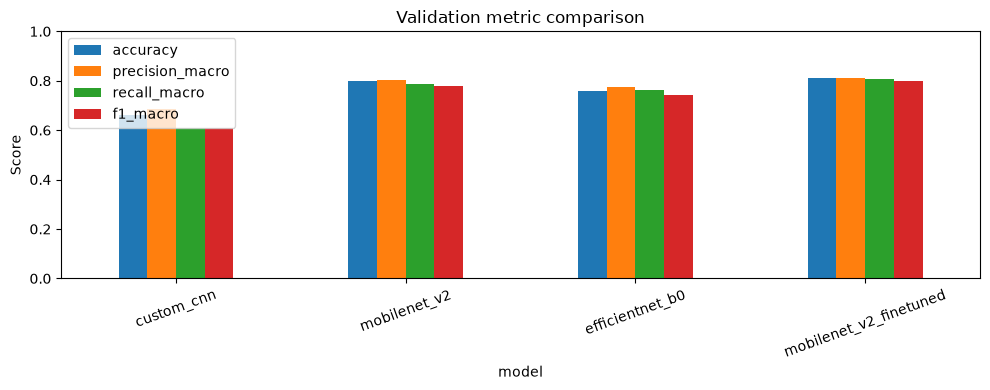

Selected for deployment: mobilenet_v2_finetuned


In [21]:
if not Path('models/deployment.json').exists():
    subprocess.run([sys.executable, '-m', 'src.train'], check=True)
if not Path('models/mobilenet_v2_finetuned.h5').exists():
    subprocess.run([sys.executable, '-m', 'src.fine_tune'], check=True)
results = json.loads(Path('models/training_results.json').read_text())
names = ['custom_cnn','mobilenet_v2','efficientnet_b0','mobilenet_v2_finetuned']
comparison = pd.DataFrame([{'model': name, **{k: results[name]['validation'][k] for k in ['accuracy','precision_macro','recall_macro','f1_macro']}, 'parameters': results[name]['parameters'], 'training_seconds': results[name]['training_seconds']} for name in names])
display(comparison.sort_values('f1_macro', ascending=False))
comparison.set_index('model')[['accuracy','precision_macro','recall_macro','f1_macro']].plot(kind='bar', figsize=(10,4), ylim=(0,1), title='Validation metric comparison')
plt.ylabel('Score'); plt.xticks(rotation=20); plt.tight_layout(); plt.show()
print('Selected for deployment:', results['selected_model'])

**Why these evaluation metrics matter.** Accuracy describes the overall share of correct images but can hide class-specific errors. Precision measures how often a predicted class is correct; low precision could cause unnecessary follow-up. Recall measures how many examples of a class are found; low tumor-class recall could mean missed cases. Macro F1 balances precision and recall while giving each class equal weight. These are research metrics, not evidence of clinical benefit or patient-level performance.

### Custom CNN

Validation accuracy was **0.660** and macro F1 was **0.607**. Training and validation accuracy/loss are shown below. The model's `.h5` file is saved under `models/`. The comparison chart above shows all four evaluation metrics; the confusion matrix below shows class-level errors.

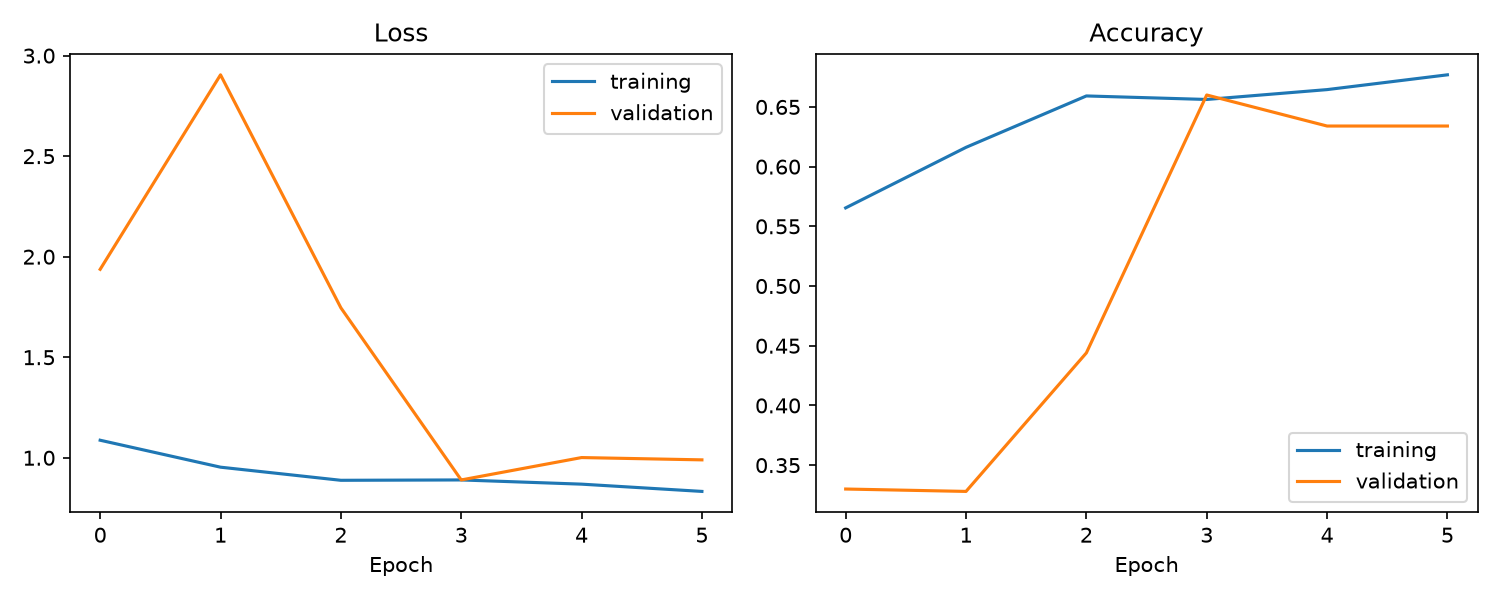

In [22]:
display(Image(filename='reports/figures/custom_cnn_training.png'))

### MobileNetV2

Validation accuracy was **0.798** and macro F1 was **0.777**. Training and validation accuracy/loss are shown below. The model's `.h5` file is saved under `models/`. The comparison chart above shows all four evaluation metrics; the confusion matrix below shows class-level errors.

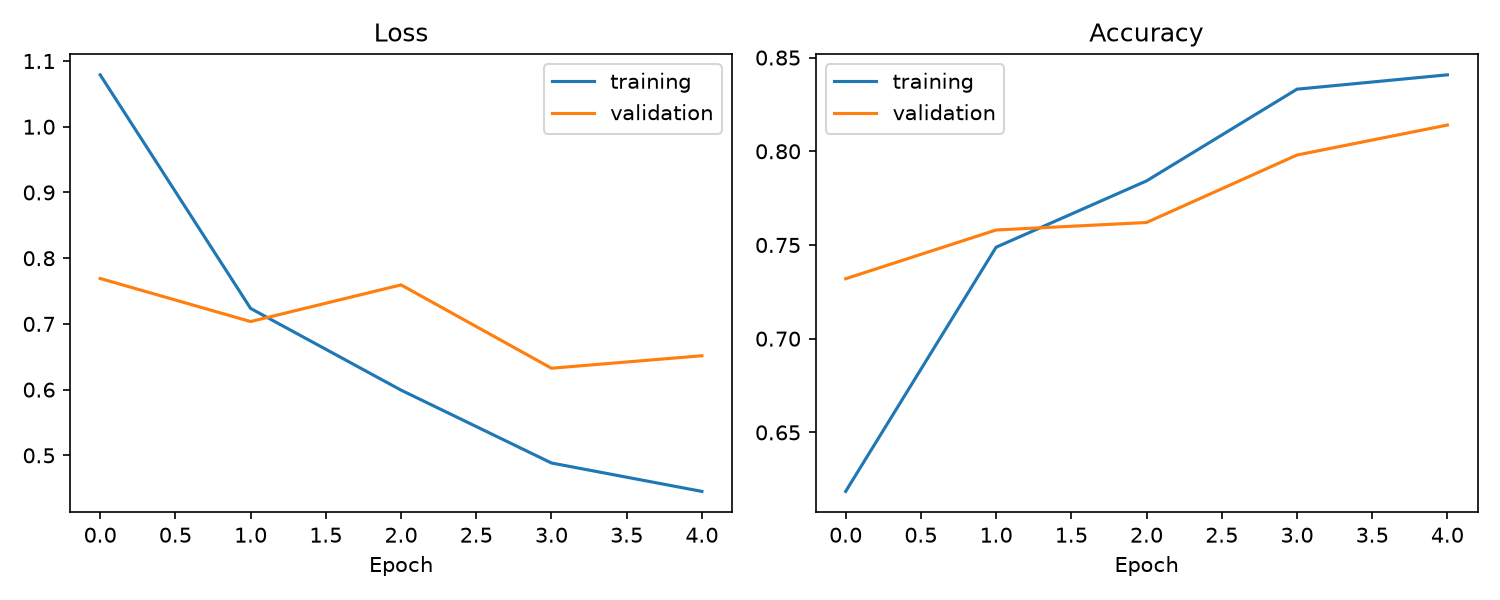

In [23]:
display(Image(filename='reports/figures/mobilenet_v2_training.png'))

### EfficientNetB0

Validation accuracy was **0.758** and macro F1 was **0.744**. Training and validation accuracy/loss are shown below. The model's `.h5` file is saved under `models/`. The comparison chart above shows all four evaluation metrics; the confusion matrix below shows class-level errors.

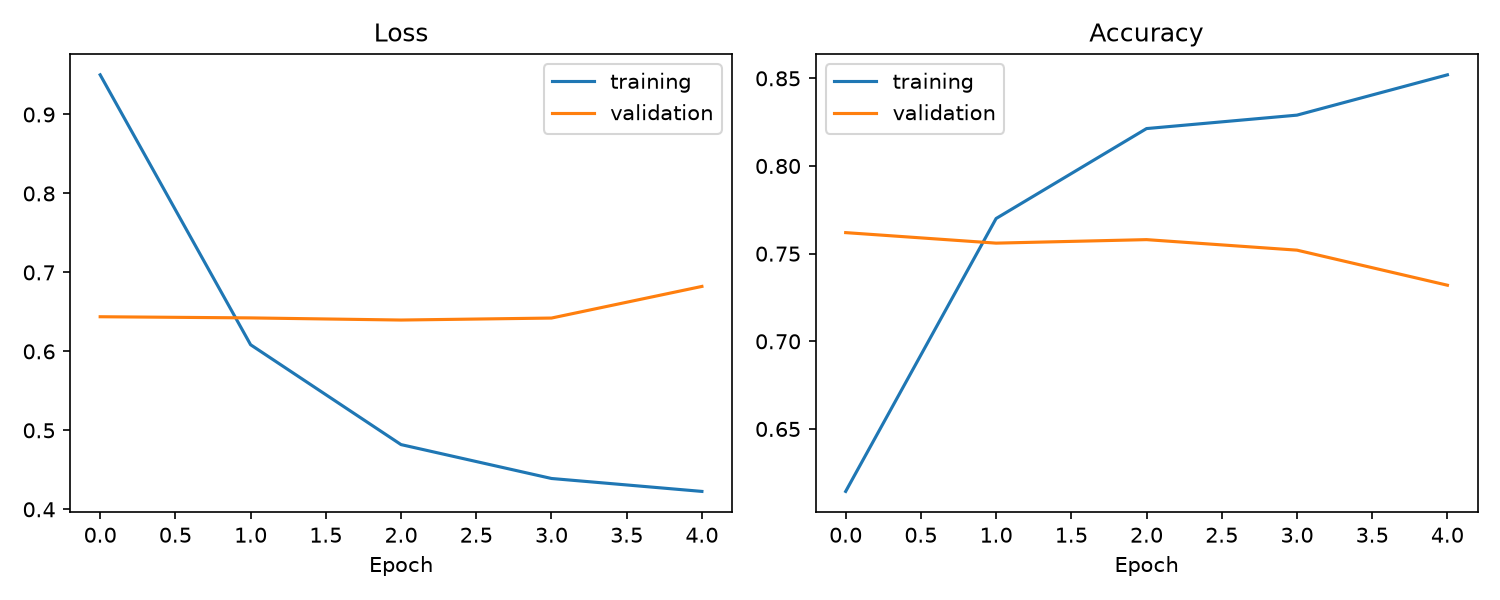

In [24]:
display(Image(filename='reports/figures/efficientnet_b0_training.png'))

### MobileNetV2 fine-tuned

Validation accuracy was **0.812** and macro F1 was **0.799**. Fine-tuning improved validation macro F1 by 0.022 over frozen MobileNetV2. Training and validation accuracy/loss are shown below. The model's `.h5` file is saved under `models/`. The comparison chart above shows all four evaluation metrics; the confusion matrix below shows class-level errors.

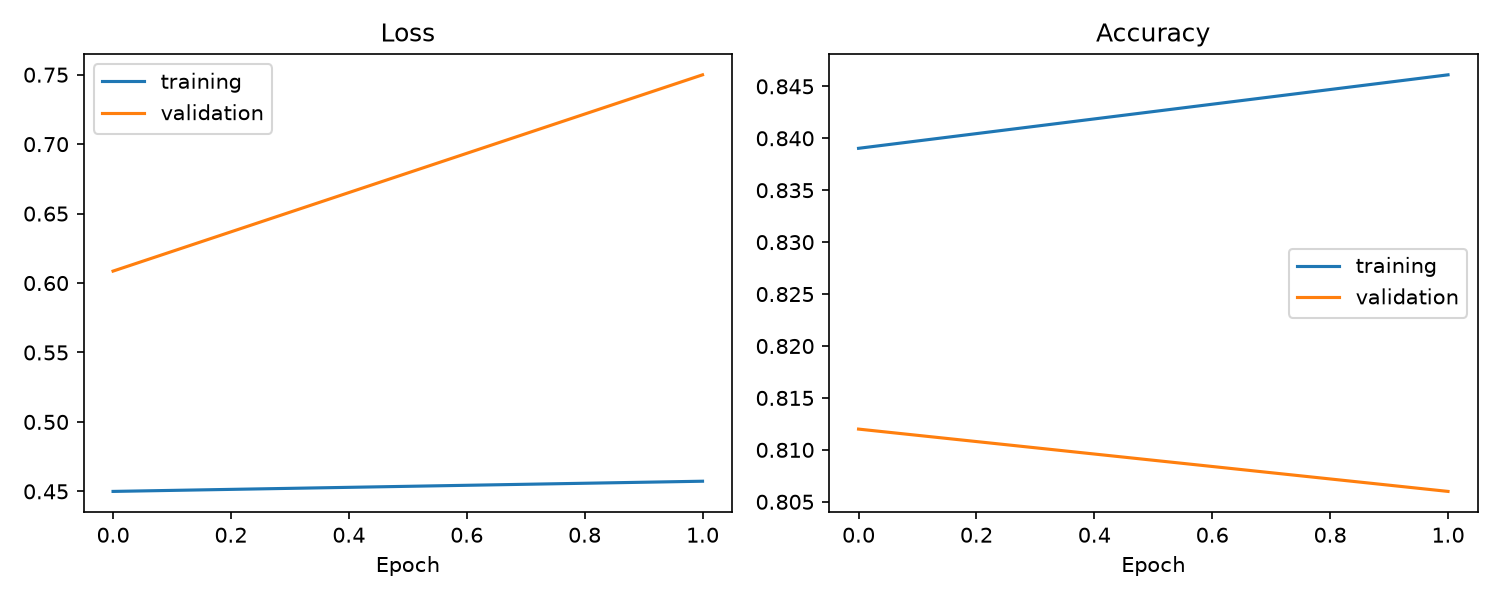

In [25]:
display(Image(filename='reports/figures/mobilenet_v2_finetuned_training.png'))

### Held-out test evaluation

Selection was fixed from validation macro F1. The following test metrics and confusion matrices are reported only after model selection. A false negative for a tumor class or a false positive for no tumor may have different consequences; neither can be judged clinically from this dataset alone.

,model,accuracy,precision_macro,recall_macro,f1_macro
0,custom_cnn,0.611336,0.653886,0.560175,0.558531
1,mobilenet_v2,0.842105,0.849651,0.835091,0.827887
2,efficientnet_b0,0.785425,0.805058,0.788363,0.778123
3,mobilenet_v2_finetuned,0.854251,0.857252,0.851646,0.845841


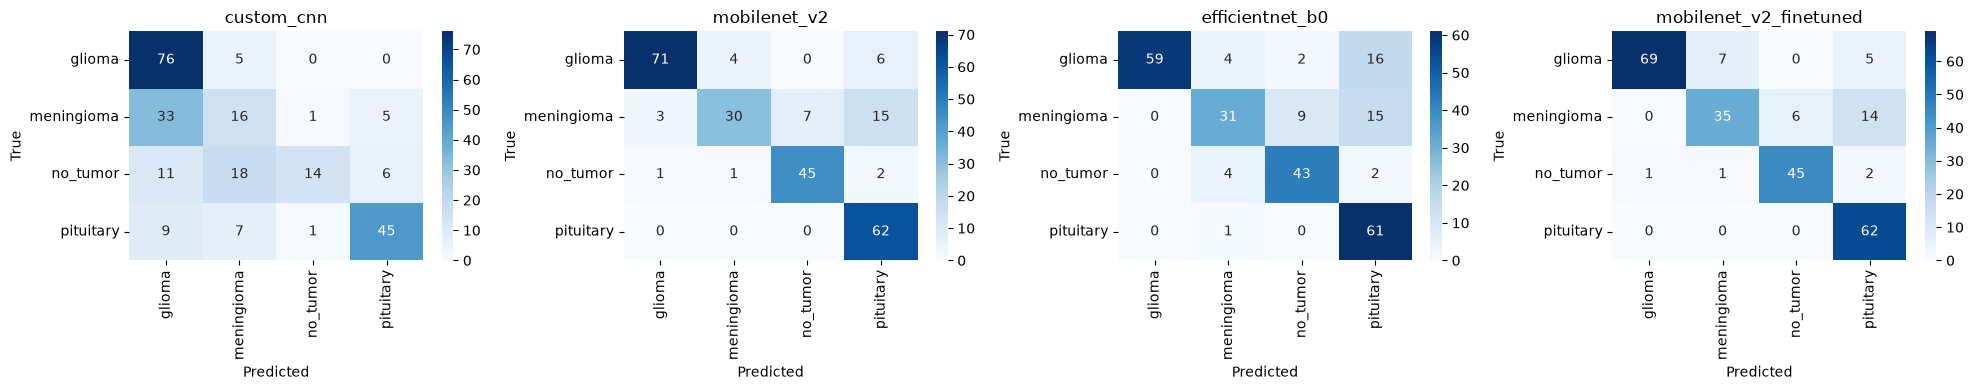

In [26]:
test_scores = pd.DataFrame([{'model': name, **{k: results[name]['test'][k] for k in ['accuracy','precision_macro','recall_macro','f1_macro']}} for name in names])
display(test_scores)
fig, axes = plt.subplots(1, len(names), figsize=(5 * len(names), 4))
for ax, name in zip(axes, names):
    sns.heatmap(results[name]['test']['confusion_matrix'], annot=True, fmt='d', cmap='Blues', ax=ax, xticklabels=['glioma','meningioma','no_tumor','pituitary'], yticklabels=['glioma','meningioma','no_tumor','pituitary'])
    ax.set(title=name, xlabel='Predicted', ylabel='True')
plt.tight_layout(); plt.show()

The selected model is **mobilenet_v2_finetuned**, chosen from validation macro F1. Its held-out test accuracy is **0.854**, macro precision **0.857**, macro recall **0.852**, and macro F1 **0.846**. The comparison considers class-balanced performance as well as parameter count and training time. These results are image-level and require external patient-level validation before any clinical claim.

## 7. Model explanation

Occlusion sensitivity hides small image patches and measures the change in the selected class score. The map shows which regions influenced one prediction; it is not a lesion segmentation or proof that the model used a medically appropriate feature.

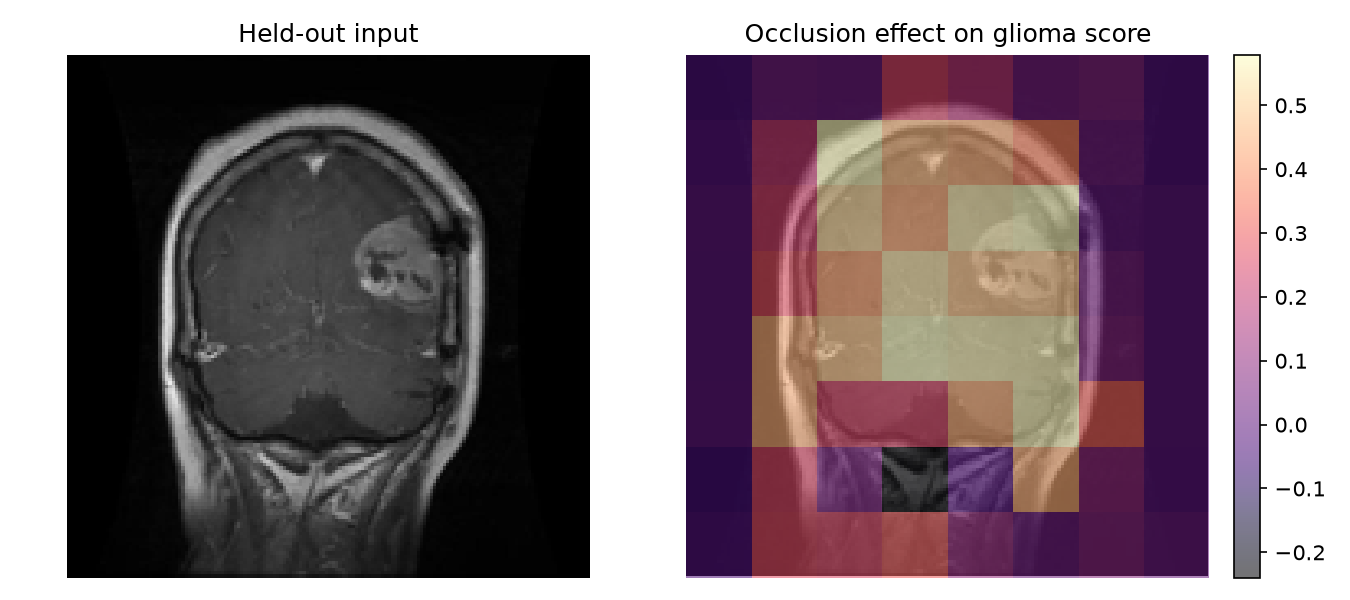

In [27]:
if not Path('reports/figures/16_occlusion_explanation.png').exists():
    subprocess.run([sys.executable, '-m', 'src.explain'], check=True)
display(Image(filename='reports/figures/16_occlusion_explanation.png'))

## 8. Streamlit deployment

`app.py` loads `models/deployment.json` and the selected `.h5` file. The **Try the model** tab accepts JPG/PNG uploads, displays the predicted class and four scores, and handles invalid files. **Model results** shows held-out metrics, model comparison, training curves, and the confusion matrix; **Explore the data** displays the 15 EDA charts. The app carries a research-use warning. The next cell builds a portable deployment ZIP. On a local machine, run `streamlit run app.py`; on Streamlit Community Cloud, publish the repository and set `app.py` as the entry point.

In [28]:
subprocess.run([sys.executable, 'scripts/package_deployment.py'], check=True)
print('Local launch: streamlit run app.py')
print('Bundle: deployment/brain_mri_streamlit.zip')

deployment/brain_mri_streamlit.zip (10.3 MB)
Local launch: streamlit run app.py
Bundle: deployment/brain_mri_streamlit.zip


## Conclusion and future work

The project delivers source-disjoint splits, 15 EDA charts, three planned statistical tests, a grouped-CV baseline, a custom CNN, two ImageNet transfer models, validation-based model choice, final test metrics, an explanation view, and a Streamlit interface. The strongest limitation is the lack of patient IDs and external validation. Future work should obtain patient-level splits, independent hospital data, label review, scanner-subgroup analysis, probability calibration, and prospective clinical evaluation. The saved Keras `.h5` files replace the generic template's pickle/joblib suggestion for deployment.